### Inverse Buckley-Leverett Physics-Informed Neural Network (IPINN)

The inverse Physics-Informed Neural Network (iPINN) aims to estimate the unknown physical parameter, the viscosity ratio 

$$ M = \frac{\mu_w}{\mu_o}, $$


directly from noisy saturation observations of the Buckley--Leverett equation. For immiscible, isothermal, horizontal two-phase flow, the wetting-phase saturation $(S_w)$ satisfies the nonlinear conservation law

$$ \phi \frac{\partial S_w}{\partial t} + v \frac{\partial f(S_w; M)}{\partial x}
= 0, \qquad (x,t)\in[0,1]\times[0,1],$$

where the fractional flow function \(f(S_w; M)\) depends explicitly on the unknown parameter \(M\).

The problem is constrained by the boundary and initial conditions:

$$
S_w(0,t) = 1 - S_{nr},
\qquad
S_w(x,0) = S_{wr}.
$$

To emulate realistic measurement conditions, the semi-analytical saturation solution is perturbed with additive noise from a univariate random function 
$( g \sim \mathcal{U}(0,1))$:

$$\hat{S}_w = S_w + g.$$

The iPINN simultaneously approximates the saturation field and infers the unknown viscosity ratio by minimizing a composite loss function that enforces data fidelity, physical consistency, and boundary/initial constraints:

$$ \mathcal{L} = \mathcal{L}_{\text{data}} + \mathcal{L}_{\mathcal{B}} + \mathcal{L}_{\text{physics}} + \mathcal{L}_{M}.$$

Here,
- $(\mathcal{L}_{\text{data}})$: mismatch between noisy observations and network predictions,
- $(\mathcal{L}_{\mathcal{B}})$: residuals from boundary and initial conditions,
- $(\mathcal{L}_{\text{physics}})$: PDE residual enforcing the Buckley--Leverett dynamics,
- $(\mathcal{L}_{M})$: regularization or consistency term for the trainable viscosity ratio.

This formulation enables robust parameter estimation even under significant noise, leveraging the PDE structure to stabilize the inverse problem.

In [1]:
# Libraries
import numpy as np
import matplotlib.pyplot as plt
import time

# Tensorflow
import tensorflow as tf
from tensorflow.python.client import device_lib

In [2]:
device_list = device_lib.list_local_devices()

for devices in device_list:
    if devices.device_type == "GPU":
        print("="*100)
        print(devices.physical_device_desc)
        print("="*100)

device: 0, name: NVIDIA GeForce RTX 3080, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:
# =============================================================================
# -------------------------  Physics parameters   ----------------------------
# =============================================================================
krwmax = 0.3      # Maximum relative permeability for water
nw = 2            # Saturation exponent for water
krnwmax = 0.8     # Maximum relative permeability for non-water (oil)
nnw = 2           # Saturation exponent for non-water (oil)
swc = 0.2         # Connate (irreducible) water saturation
snwr = 0.2        # Residual saturation of the non-water phase
muw = 1.0e-3      # Viscosity of water (Pa.s)
munw = 5.0e-3     # Viscosity of non-water phase (Pa.s)  <-- true value (for synthetic data)
qt = 0.1          # Flow rate (arbitrary units)
A = 1.0           # Cross-sectional area
phi = 0.2         # Porosity
l = 1.0           # Length of spacial domain
t = 1.0           # Length of spacial domain

# ---------------------  Discretization parameters   ------------------------
times = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0] # Times for simulation (arbitrary units)

Nx = 100
Nt = 100

dt = t / Nt
dx = l / Nx

In [4]:
# =============================================================================
# -------------------------  Brooks-Corey Model   ----------------------------
# =============================================================================
class BrooksCorey:
    """Brooks-Corey relative permeability model"""
    def __init__(self, swc=0.2, snwr=0.2, nw=2.0, nnw=2.0,
                 krwmax=0.3, krnwmax=0.8, muw=1.0e-3, munw=5.0e-3):
        self.swc = swc
        self.snwr = snwr
        self.nw = nw
        self.nnw = nnw
        self.krwmax = krwmax
        self.krnwmax = krnwmax
        self.muw = muw
        self.munw = munw

        self.compute_shock_properties()

    def normalized_saturation(self, S):
        S_star = (S - self.swc) / (1.0 - self.swc - self.snwr)
        S_star = tf.clip_by_value(S_star, 0.0, 1.0)
        return S_star

    def kr_water(self, S):
        S_star = self.normalized_saturation(S)
        return self.krwmax * tf.pow(S_star, self.nw)

    def kr_nonwater(self, S):
        S_star = self.normalized_saturation(S)
        return self.krnwmax * tf.pow(1.0 - S_star, self.nnw)

    def fractional_flow(self, S, M_ratio=None):
        """
        If M_ratio is None, uses the default ratio from muw, munw.
        """
        krw = self.kr_water(S)
        krnw = self.kr_nonwater(S)
        eps = 1e-10

        M_eff = (self.muw / self.munw) if M_ratio is None else M_ratio
        M = (krnw / (krw + eps)) * M_eff
        fw = 1.0 / (1.0 + M)
        return fw

    def compute_shock_properties(self):
        S_vals = np.linspace(self.swc + 0.001, 1.0 - self.snwr, 1000)
        S_tensor = tf.constant(S_vals.reshape(-1, 1), dtype=tf.float32)

        fw_vals = self.fractional_flow(S_tensor).numpy().flatten()

        S_swc_tensor = tf.constant([[self.swc]], dtype=tf.float32)
        fw_swc = self.fractional_flow(S_swc_tensor).numpy()[0, 0]

        slopes = (fw_vals - fw_swc) / (S_vals - self.swc)
        idx_shock = np.argmax(slopes)

        self.sw_tangent = S_vals[idx_shock]
        self.fw_tangent = fw_vals[idx_shock]
        self.fw_swc = fw_swc
        self.alpha_tangent = (self.fw_tangent - fw_swc) / (self.sw_tangent - self.swc)

        print(f"\nShock properties (Welge tangent):")
        print(f"  fw(swc): {fw_swc:.4f}")
        print(f"  Shock saturation (sw_tangent): {self.sw_tangent:.4f}")
        print(f"  fw at shock: {self.fw_tangent:.4f}")
        print(f"  Shock slope (alpha): {self.alpha_tangent:.4f}\n")

# =============================================================================
# ------------------------  Semi-Analytic Solution   --------------------------
# =============================================================================
class analytic_solution():
    def __init__(self, Swc, Sor, krw0, kro0, nw, no, mu_w, mu_o,
                 Nx, Nt, A, qt, phi, fw_tangent, sw_tangent, L, T):
        self.Swc = Swc
        self.Sor = Sor
        self.krw0 = krw0
        self.kro0 = kro0
        self.nw = nw
        self.no = no
        self.mu_w = mu_w
        self.mu_o = mu_o
        self.Nx = Nx
        self.Nt = Nt
        self.A = A
        self.qt = qt
        self.phi = phi
        self.L = L
        self.T = T

        self.fw_tangent = fw_tangent
        self.sw_tangent = sw_tangent
        self.dx = L / (Nx-1)
        self.dt = T / (Nt-1)

        self.v_shock = qt / A / phi * (fw_tangent)/(sw_tangent-Swc)
        self.ttf = np.arange(self.Nt) * self.dt
        self.xf = self.v_shock * self.ttf

        self.x_test = np.arange(Nx) * self.dx

    def Swe(self, Sw):
        return np.clip((Sw - self.Swc) / (1 - self.Swc - self.Sor), 0, 1)

    def krw(self, Sw):
        return self.krw0 * self.Swe(Sw) ** self.nw

    def kro(self, Sw):
        return self.kro0 * (1 - self.Swe(Sw)) ** self.no

    def fw(self, Sw):
        return (self.krw(Sw) / self.mu_w) / (self.krw(Sw) / self.mu_w + self.kro(Sw) / self.mu_o)

    def dfw_dSw(self, Sw, eps=1e-6):
        return (self.fw(Sw + eps) - self.fw(Sw - eps)) / (2 * eps)

    def create_solution(self):
        saturation_profiles = []

        for i in range(self.Nt):
            if self.xf[i] <= self.L:
                xs = len(self.x_test[self.x_test < self.xf[i]])

                if xs > 0:
                    y = np.linspace(1-self.Sor, self.sw_tangent, xs)
                    s_x = self.dfww_dSw(y) * self.qt / self.A / self.phi * self.ttf[i]
                    xvals = np.linspace(0, self.xf[i], xs)
                    yinterp = np.interp(xvals, s_x, y)
                    pad_length = self.Nx - len(yinterp)
                    profile = np.pad(yinterp, (0, pad_length), 'constant', constant_values=self.Swc)
                else:
                    profile = np.full(self.Nx, self.Swc)
            else:
                y = np.linspace(1-self.Sor, self.sw_tangent, self.Nx)
                s_x = self.dfww_dSw(y) * self.qt / self.A / self.phi * self.ttf[i]
                yinterp = np.interp(self.x_test, s_x, y)
                yinterp[self.x_test > self.xf[i]] = self.sw_tangent
                profile = yinterp

            saturation_profiles.append(profile)

        return saturation_profiles

    # Fix typo in dfw_dSw usage above
    def dfww_dSw(self, Sw, eps=1e-6):
        return self.dfw_dSw(Sw, eps)

In [5]:
# =============================================================================
# ----------------  Initialize BC model and synthetic data   ------------------
# =============================================================================
bc_model = BrooksCorey(swc=swc, snwr=snwr, nw=nw, nnw=nnw,
                       krwmax=krwmax, krnwmax=krnwmax,
                       muw=muw, munw=munw)

semi = analytic_solution(Swc=swc, Sor=snwr, krw0=krwmax, kro0=krnwmax, nw=nw, no=nnw,
                         mu_w=muw, mu_o=munw, Nx=Nx, Nt=Nt, A=A, qt=qt, phi=phi,
                         fw_tangent=bc_model.fw_tangent, sw_tangent=bc_model.sw_tangent,
                         L=l, T=l)

u = np.array(semi.create_solution())
u_noisy = u + 0.2*0 * np.random.random(u.shape) - 0.1*0


Shock properties (Welge tangent):
  fw(swc): 0.0000
  Shock saturation (sw_tangent): 0.5542
  fw at shock: 0.7956
  Shock slope (alpha): 2.2463



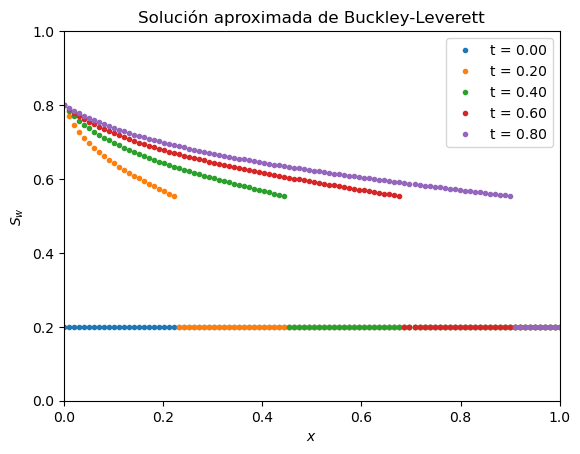

In [6]:
x = np.linspace(0, l, Nx)

plt.figure()
for i in range(Nt):
    if i % 20 == 0:
        plt.plot(x, u_noisy[i],'.', label=f't = {i*dt:.2f}')
plt.xlabel("$x$")
plt.ylabel("$S_{w}$")
plt.title("Solución aproximada de Buckley-Leverett")
plt.ylim([0.0, 1.0])
plt.xlim([0,1])
plt.legend()
plt.show()

In [7]:
# =============================================================================
# -----------------------  (noisy) Data generation   -------------------------
# =============================================================================
Use_data = True
lambda_data = 5.0

data_array = u_noisy.T.copy()

x_data_coords = np.linspace(0, l, data_array.shape[0])
t_data_coords = np.linspace(0, t, data_array.shape[1])

X_data_mesh, T_data_mesh = np.meshgrid(x_data_coords, t_data_coords, indexing='ij')
x_data_flat = X_data_mesh.flatten()
t_data_flat = T_data_mesh.flatten()
s_data_flat = data_array.flatten()

if Use_data:
    x_data_tensor = tf.Variable(x_data_flat.reshape(-1, 1), dtype=tf.float32)
    t_data_tensor = tf.Variable(t_data_flat.reshape(-1, 1), dtype=tf.float32)
    s_data_tensor = tf.constant(s_data_flat.reshape(-1, 1), dtype=tf.float32)

    print(f"\nData loaded: {len(x_data_flat)} observation points")
    print(f"Data domain: x ∈ [{x_data_flat.min():.2f}, {x_data_flat.max():.2f}], "
          f"t ∈ [{t_data_flat.min():.2f}, {t_data_flat.max():.2f}]")
    print(f"Saturation range: S ∈ [{s_data_flat.min():.3f}, {s_data_flat.max():.3f}]")
    print(f"Data loss weight: {lambda_data}")
else:
    x_data_tensor = None
    t_data_tensor = None
    s_data_tensor = None
    print("No data for the PINN training")

# =============================================================================
# --------------------------  Collocation points   ----------------------------
# =============================================================================
print("Creating collocation points...")
x_col = np.linspace(0.001, l, 500).reshape(-1, 1)
t_col = np.linspace(0.00, max(times), 100).reshape(-1, 1)

X, T = np.meshgrid(x_col.flatten(), t_col.flatten(), indexing='ij')
X = tf.Variable(X.reshape(-1, 1), dtype=tf.float32)
T = tf.Variable(T.reshape(-1, 1), dtype=tf.float32)
print("Done!")


Data loaded: 10000 observation points
Data domain: x ∈ [0.00, 1.00], t ∈ [0.00, 1.00]
Saturation range: S ∈ [0.200, 0.800]
Data loss weight: 5.0
Creating collocation points...
Done!


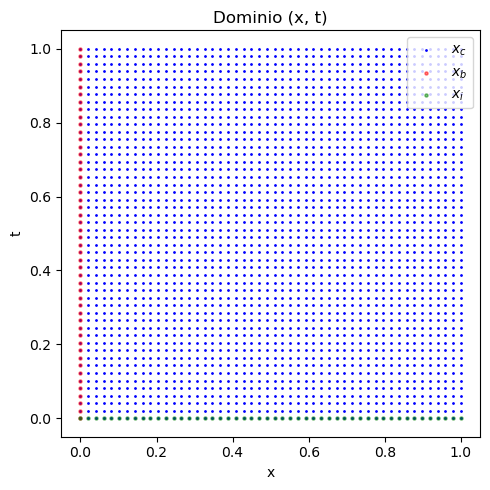

In [8]:
X_np = X.numpy()
T_np = T.numpy()

x_c = np.linspace(0,1,50).reshape(-1, 1)
y_c = np.linspace(0,1,50).reshape(-1, 1)
x_c, y_c = np.meshgrid(x_c.flatten(), y_c.flatten(), indexing='ij')

x_c_b = np.zeros(50)
y_c_b = np.linspace(0,1,50)

# Plot meshgrid
plt.figure(figsize=(5, 5))
plt.scatter(x_c, y_c , color='blue', s=1.0, alpha=1.0, label='$x_{c}$')
plt.scatter(x_c_b, y_c_b , color='red', s=5.0, alpha=0.5, label='$x_{b}$')
plt.scatter(y_c_b, x_c_b , color='green', s=5.0, alpha=0.5, label='$x_{i}$')
#if Use_data:
#    plt.scatter(x_data_flat[::2], t_data_flat[::2], color='red', s=0.2, alpha=0.5, label='$x_{d}$')
plt.xlabel("x")
plt.ylabel("t")
plt.title("Dominio (x, t)")
plt.legend()
plt.tight_layout()
plt.show()

The parameter set includes both the weights and biases, together with the additional trainable variables, and is denoted by

$$\theta = \{ \mathbf{W}, \mathbf{b},M \}.$$

All parameters in this set are optimized simultaneously during training. At each epoch, the update rule follows the standard gradient‑based iteration

$$\theta^{k+1}=\theta^{k}+\eta \nabla_{\theta}\mathcal{L}.$$

where $\eta$ is the learning rate and $\mathcal{L}$ is the loss function.

In [9]:
# =============================================================================
# ------------------------------  PINN model   --------------------------------
# =============================================================================
class PINN(tf.keras.Model):
    def __init__(self, neurons, layers, dim_in, dim_out):
        super(PINN, self).__init__()
        self.fci = tf.keras.layers.Dense(neurons, activation=None)
        self.fco = tf.keras.layers.Dense(dim_out, activation=None)
        self.tanh = tf.keras.layers.Activation('tanh')
        self.mlps = []
        for _ in range(layers):
            self.mlps.append(tf.keras.layers.Dense(neurons, activation=None))

    def call(self, x, t):
        x_i = tf.concat([x, t], axis=1)
        x_out = self.fci(x_i)
        for mlp_x in self.mlps:
            x_out = mlp_x(x_out)
            x_out = self.tanh(x_out)
        x_out = self.fco(x_out)
        return x_out

# =============================================================================
# -----------------  Physics-informed loss with trainable M   -----------------
# =============================================================================
def physics_informed_loss_diff(model, bc_model, x, t, qt, phi, A,
                               M_inv,
                               x_data=None, t_data=None, s_data=None, lambda_data=1.0):

    with tf.GradientTape(persistent=True) as tape:
        tape.watch(x)
        tape.watch(t)

        sw_pred = model(x, t)

        fw = bc_model.fractional_flow(sw_pred, M_ratio=M_inv)

        alpha = bc_model.alpha_tangent
        sw_tangent = bc_model.sw_tangent
        fw_swc = bc_model.fw_swc

        fw = tf.where(sw_pred < sw_tangent,
                      fw_swc + alpha * (sw_pred - swc),
                      fw)

    sw_t = tape.gradient(sw_pred, t)
    fw_x = tape.gradient(fw, x)
    del tape

    residual = sw_t + (qt / phi / A) * fw_x

    t_zero = tf.zeros_like(t)
    sw_initial = model(x, t_zero)

    x_zero = tf.zeros_like(x)
    sw_boundary = model(x_zero, t)

    loss_physics = tf.reduce_mean(tf.abs(residual))
    loss_initial = tf.reduce_mean(tf.abs(sw_initial - swc))
    loss_boundary = tf.reduce_mean(tf.abs(sw_boundary - (1 - snwr)))

    loss_data = tf.constant(0.0, dtype=tf.float32)
    if x_data is not None and t_data is not None and s_data is not None:
        s_pred_data = model(x_data, t_data)
        loss_data = tf.reduce_mean(tf.abs(s_pred_data - s_data))

    total_loss = loss_physics + loss_boundary + loss_initial + lambda_data * loss_data

    return total_loss, loss_physics, loss_boundary, loss_initial, loss_data

@tf.function
def train_step(model, bc_model, optimizer, X, T, qt, phi, A,
               M_inv,
               x_data, t_data, s_data, lambda_data):

    with tf.GradientTape() as tape:
        loss, loss_physics, loss_boundary, loss_initial, loss_data = \
            physics_informed_loss_diff(model, bc_model, X, T, qt, phi, A,
                                       M_inv,
                                       x_data, t_data, s_data, lambda_data)

    train_vars = model.trainable_variables + [M_inv]
    gradients = tape.gradient(loss, train_vars)
    optimizer.apply_gradients(zip(gradients, train_vars))

    return loss, loss_physics, loss_boundary, loss_initial, loss_data

In [10]:
# =============================================================================
# --------------------- Initialize PINN and trainable M -----------------------
# =============================================================================
print("Initializing PINN model...")
model = PINN(neurons=16, layers=7, dim_in=2, dim_out=1)
optimizer = tf.keras.optimizers.Adam(learning_rate=5e-4)

M_true = muw / munw
M_inv = tf.Variable(10 * M_true, dtype=tf.float32, trainable=True, name="M_inv")
print(f"True M = {M_true:.3f}, initial guess M_inv = {M_inv.numpy():.3f}")

epochs_log = []
loss_totals = []
loss_physics_acc = []
loss_init_acc = []
loss_boundary_acc = []
loss_data_acc = []
M_log = []

num_epochs = 20000
print(f"\nStarting training for {num_epochs} epochs...\n")
starting_time = time.time()
print("="*100)

for epoch in range(num_epochs):
    loss, loss_physics, loss_boundary, loss_initial, loss_data = train_step(
        model, bc_model, optimizer, X, T, qt, phi, A,
        M_inv,
        x_data_tensor, t_data_tensor, s_data_tensor, lambda_data)

    if epoch % 500 == 0 or epoch + 1 == num_epochs:
        print(f"Epoch {epoch}/{num_epochs}, Loss: {loss.numpy():.5f}, "
              f"Physics: {loss_physics.numpy():.5f}, "
              f"Initial: {loss_initial.numpy():.5f}, "
              f"Boundary: {loss_boundary.numpy():.5f}, "
              f"Data: {loss_data.numpy():.5f}, "
              f"M_inv: {M_inv.numpy():.4f}")

    epochs_log.append(epoch)
    loss_totals.append(loss.numpy())
    loss_physics_acc.append(loss_physics.numpy())
    loss_init_acc.append(loss_initial.numpy())
    loss_boundary_acc.append(loss_boundary.numpy())
    loss_data_acc.append(loss_data.numpy())
    M_log.append(M_inv.numpy())

print("="*100)
print("\nTraining complete!")
print("Training time %1.5f minutes" % ((time.time()-starting_time)/60.0))

print(f"\nTrue M = {M_true:.4f}")
print(f"Inferred M = {M_inv.numpy():.4f}")

Initializing PINN model...
True M = 0.200, initial guess M_inv = 2.000

Starting training for 20000 epochs...

Epoch 0/20000, Loss: 4.26880, Physics: 0.19775, Initial: 0.17196, Boundary: 0.97198, Data: 0.58542, M_inv: 2.0000
Epoch 500/20000, Loss: 0.48277, Physics: 0.14742, Initial: 0.02705, Boundary: 0.09216, Data: 0.04323, M_inv: 1.6925
Epoch 1000/20000, Loss: 0.33677, Physics: 0.11544, Initial: 0.01085, Boundary: 0.08953, Data: 0.02419, M_inv: 1.3910
Epoch 1500/20000, Loss: 0.28176, Physics: 0.12877, Initial: 0.00914, Boundary: 0.07209, Data: 0.01435, M_inv: 1.0168
Epoch 2000/20000, Loss: 0.23973, Physics: 0.08895, Initial: 0.02138, Boundary: 0.02289, Data: 0.02130, M_inv: 0.5567
Epoch 2500/20000, Loss: 0.07047, Physics: 0.01853, Initial: 0.00276, Boundary: 0.02159, Data: 0.00552, M_inv: 0.2149
Epoch 3000/20000, Loss: 0.06436, Physics: 0.01236, Initial: 0.00632, Boundary: 0.01706, Data: 0.00573, M_inv: 0.2006
Epoch 3500/20000, Loss: 0.04998, Physics: 0.01140, Initial: 0.00431, Bound

In [11]:
# =============================================================================
# ---------------------- Calculating prediction array -------------------------
# =============================================================================
x_test = np.linspace(0, l, Nx)
dt = 1 / Nt
u_pred = np.zeros([Nt, Nx])

for i in range(Nt):
    t_val = i * dt
    x_plot = tf.constant(x_test, dtype=tf.float32)
    x_plot = tf.reshape(x_plot, (-1, 1))
    t_plot = tf.fill(tf.shape(x_plot), t_val)
    u_pred[i] = model(x_plot, t_plot).numpy().reshape(100,)

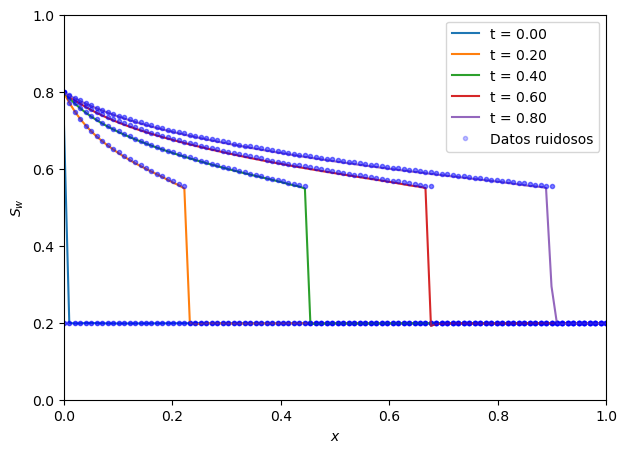

In [12]:
# =============================================================================
# ----------------------- Plotting model predictions --------------------------
# =============================================================================
plt.figure(figsize=[7,5])

for i in range(100):
    if i%20 == 0:
        plt.plot(x_test, u_pred[i], label=f't = {i*dt:.2f}')
        plt.plot(x_test, u_noisy[i], "b.",alpha=0.5)

plt.plot(x_test, u_noisy[0], "b.",alpha=0.25, label="Datos ruidosos")
plt.xlabel("$x$")
plt.ylabel("$S_{w}$")
plt.ylim([0.0, 1.0])
plt.xlim([0,1])
plt.legend()
plt.show()

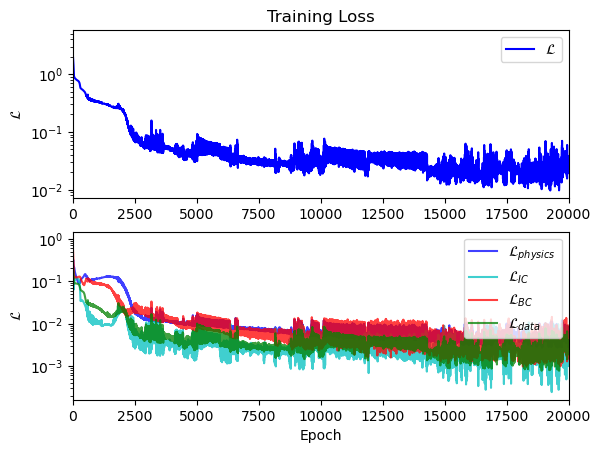

In [13]:
# =============================================================================
# -------------------------- Plotting loss curves -----------------------------
# =============================================================================
plt.figure()
plt.subplot(2,1,1)
plt.semilogy(epochs_log, loss_totals,"b-", label="$\mathcal{L}$")
plt.title('Training Loss')
plt.ylabel("$\mathcal{L}$")
plt.legend()
plt.xlim([0, num_epochs])
plt.yscale("log")
plt.subplot(2,1,2)
plt.semilogy(epochs_log, loss_physics_acc,"b",alpha=0.75, label="$\mathcal{L}_{physics}$")
plt.semilogy(epochs_log, loss_init_acc,"c",alpha=0.75, label='$\mathcal{L}_{IC}$')
plt.semilogy(epochs_log, loss_boundary_acc,"r",alpha=0.75, label='$\mathcal{L}_{BC}$')
plt.semilogy(epochs_log, loss_data_acc,"g",alpha=0.75, label='$\mathcal{L}_{data}$')
plt.ylabel("$\mathcal{L}$")
plt.legend()
plt.yscale("log")
plt.xlim([0, num_epochs])
plt.xlabel('Epoch')
plt.show()

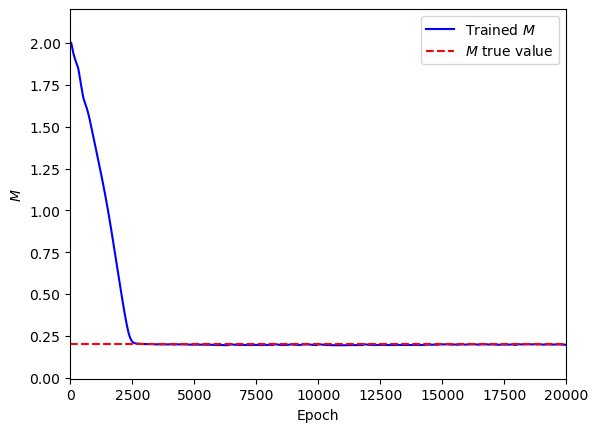

In [14]:
# =============================================================================
# -------------------------- Plotting M Training ------------------------------
# =============================================================================

plt.figure()
plt.plot(M_log, "b-", label="Trained $M$")
plt.hlines(M_true, xmin=0.0, xmax=num_epochs,color="red",
           label="$M$ true value", linestyles='dashed')
plt.ylim([np.min(M_log)-0.2,
          np.max(M_log)+0.2])
plt.xlim([0, num_epochs])
plt.ylabel('$M$')
plt.xlabel('Epoch')
plt.legend()
plt.show()